In [1]:
%pip install opencv-python matplotlib numpy

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   - -------------------------------------- 1.6/44.0 MB 11.4 MB/s eta 0:00:04
   ---- ----------------------------------- 4.5/44.0 MB 12.9 MB/s eta 0:00:04
   ------- -------------------------------- 7.9/44.0 MB 13.8 MB/s eta 0:00:03
   ---------- ----------------------------- 11.5/44.0 MB 15.1 MB/s eta 0:00:03
   --------------- ------------------------ 16.8/44.0 MB 17.0 MB/s eta 0:00:02
   -------------------- ------------------- 22.0/44.0 MB 18.4 MB/s eta 0:00:02
   ------------------------- -------------- 28.0/44.0 MB 20.4 MB/s eta 0:00:01
   --------------------------- ------------ 30.1/44.0 MB 18.9 MB/s eta 0:00:01
   ------------------------------ --------- 33.0/44.0 MB 18.3 MB/s eta 0:00:01
   -------------------------------- ------- 35.4/44.0 MB 17.5 MB/s eta 0:00:01
   --------------------------------- ------ 37.2/44.0 MB 16.7 MB/s eta 0:00:01
   ----------------------------------- ---- 39.1/44.0 MB 16.0 MB

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


Image loaded successfully!
Image dimensions: (479, 417)


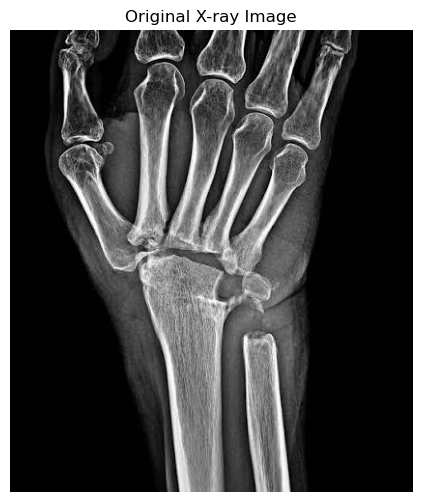

In [3]:
image_path = r"C:\Users\gemin\OneDrive\Bone Fracture\bone fracture.jpg"

image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError(
        "Image not found. Check the filename and folder."
    )

print("Image loaded successfully!")
print("Image dimensions:", image.shape)

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.title("Original X-ray Image")
plt.axis("off")
plt.show()

Noise Filtering

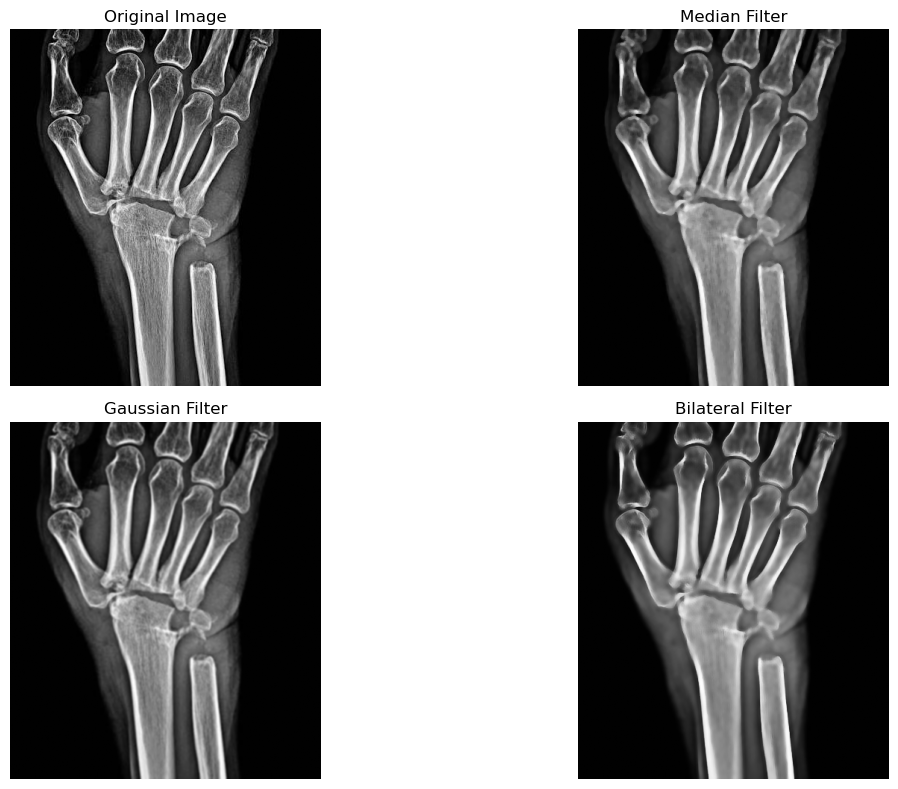

In [4]:
# 1. Median Filter
median_filtered = cv2.medianBlur(image, 5)

# 2. Gaussian Filter
gaussian_filtered = cv2.GaussianBlur(
    image, (5, 5), 0
)

# 3. Bilateral Filter
bilateral_filtered = cv2.bilateralFilter(
    image, 9, 75, 75
)

# Display the results
images = [
    ("Original Image", image),
    ("Median Filter", median_filtered),
    ("Gaussian Filter", gaussian_filtered),
    ("Bilateral Filter", bilateral_filtered)
]

plt.figure(figsize=(14, 8))

for i, (title, img) in enumerate(images, 1):
    plt.subplot(2, 2, i)
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

Histogram enhancement

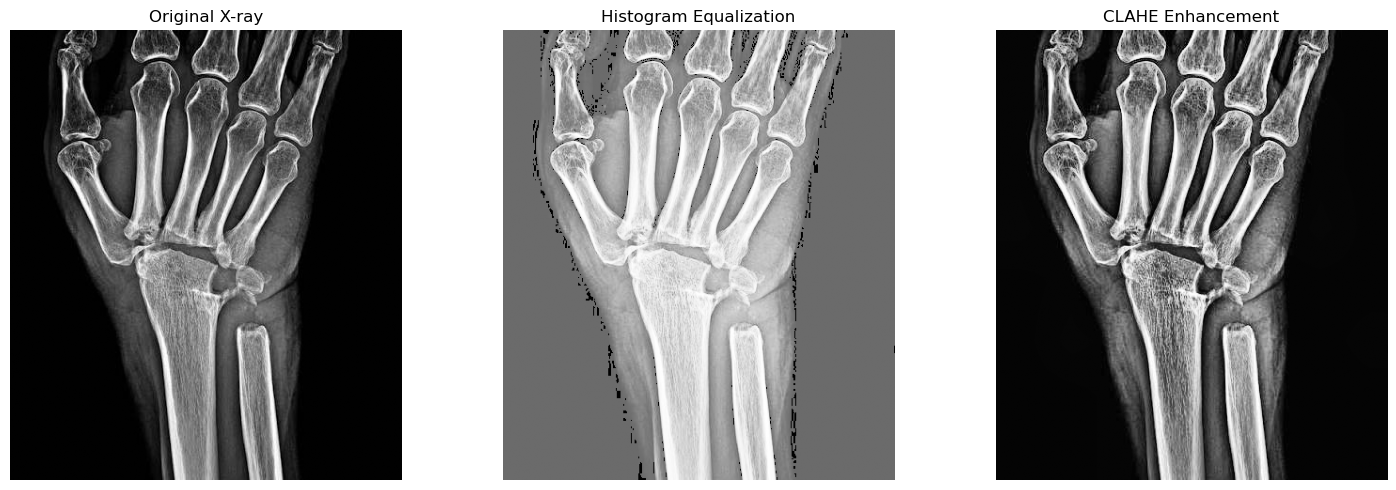

In [5]:
# Histogram Equalization
hist_equalized = cv2.equalizeHist(image)

# CLAHE
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_image = clahe.apply(image)

images = [
    ("Original X-ray", image),
    ("Histogram Equalization", hist_equalized),
    ("CLAHE Enhancement", clahe_image)
]

plt.figure(figsize=(15, 5))

for i, (title, img) in enumerate(images, 1):
    plt.subplot(1, 3, i)
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

Image segmentation

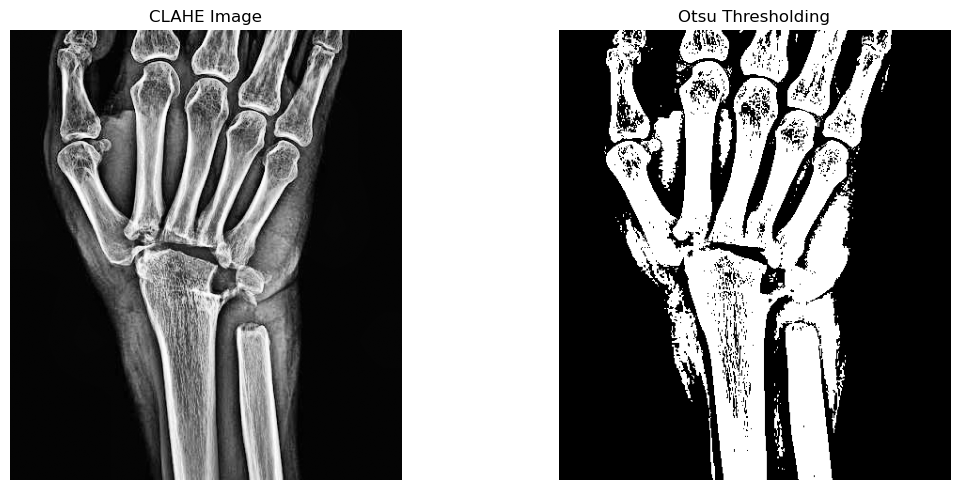

In [6]:
_, threshold_image = cv2.threshold(
    clahe_image,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(clahe_image, cmap="gray")
plt.title("CLAHE Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(threshold_image, cmap="gray")
plt.title("Otsu Thresholding")
plt.axis("off")

plt.tight_layout()
plt.show()

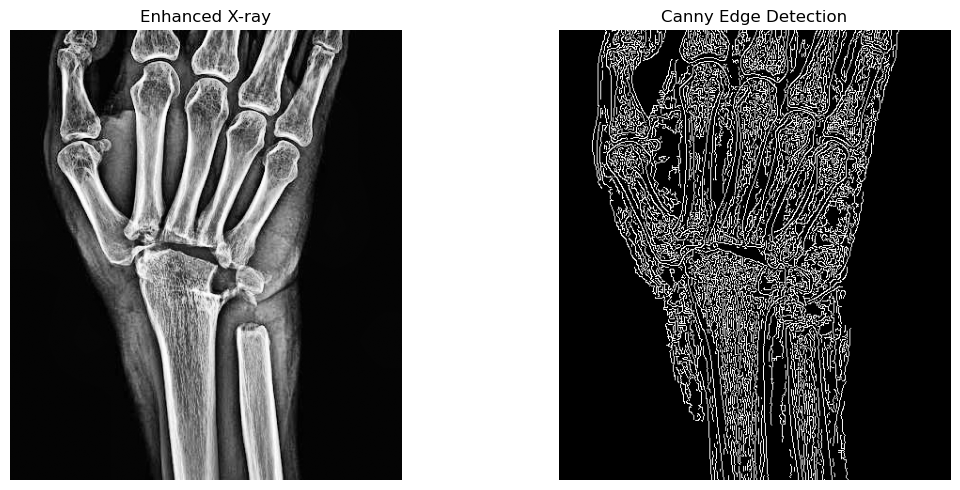

In [7]:
edges = cv2.Canny(
    clahe_image,
    threshold1=50,
    threshold2=150
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(clahe_image, cmap="gray")
plt.title("Enhanced X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

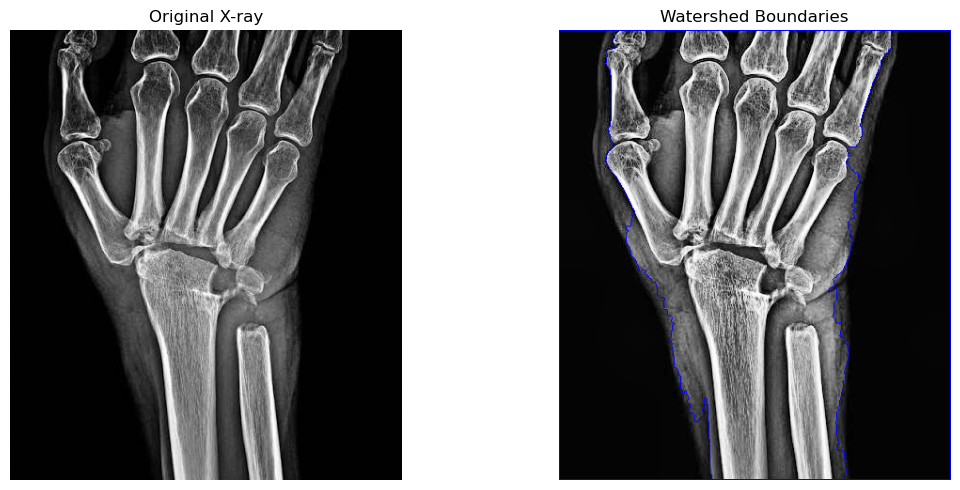

In [8]:
# Convert grayscale image to BGR for watershed
watershed_input = cv2.cvtColor(
    clahe_image, cv2.COLOR_GRAY2BGR
)

# Create a binary foreground/background mask
_, binary = cv2.threshold(
    clahe_image,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove small noise
kernel = np.ones((3, 3), np.uint8)

opening = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel,
    iterations=2
)

# Identify background
sure_background = cv2.dilate(
    opening, kernel, iterations=3
)

# Estimate foreground
distance = cv2.distanceTransform(
    opening, cv2.DIST_L2, 5
)

_, sure_foreground = cv2.threshold(
    distance,
    0.4 * distance.max(),
    255,
    cv2.THRESH_BINARY
)

sure_foreground = np.uint8(sure_foreground)

# Identify uncertain areas
unknown = cv2.subtract(
    sure_background, sure_foreground
)

# Create watershed markers
_, markers = cv2.connectedComponents(
    sure_foreground
)

markers = markers + 1
markers[unknown == 255] = 0

# Apply Watershed
markers = cv2.watershed(
    watershed_input, markers
)

# Mark boundaries in red
watershed_result = watershed_input.copy()
watershed_result[markers == -1] = [255, 0, 0]

# Display the result
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(
    watershed_result, cv2.COLOR_BGR2RGB
))
plt.title("Watershed Boundaries")
plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
output_folder = Path("processed_images")
output_folder.mkdir(exist_ok=True)

cv2.imwrite(
    str(output_folder / "median_filtered.png"),
    median_filtered
)

cv2.imwrite(
    str(output_folder / "gaussian_filtered.png"),
    gaussian_filtered
)

cv2.imwrite(
    str(output_folder / "bilateral_filtered.png"),
    bilateral_filtered
)

cv2.imwrite(
    str(output_folder / "histogram_equalized.png"),
    hist_equalized
)

cv2.imwrite(
    str(output_folder / "clahe.png"),
    clahe_image
)

cv2.imwrite(
    str(output_folder / "thresholding.png"),
    threshold_image
)

cv2.imwrite(
    str(output_folder / "edge_detection.png"),
    edges
)

cv2.imwrite(
    str(output_folder / "watershed.png"),
    watershed_result
)

print("Processed images saved successfully!")

Processed images saved successfully!
